First five rows:
   Unnamed: 0  YearsExperience   Salary
0           0              1.2  39344.0
1           1              1.4  46206.0
2           2              1.6  37732.0
3           3              2.1  43526.0
4           4              2.3  39892.0
Slope: 9423.815323030976
Intercept: 24380.201479473704
Mean Squared Error: 49830096.855908394
R2 Score: 0.9024461774180497


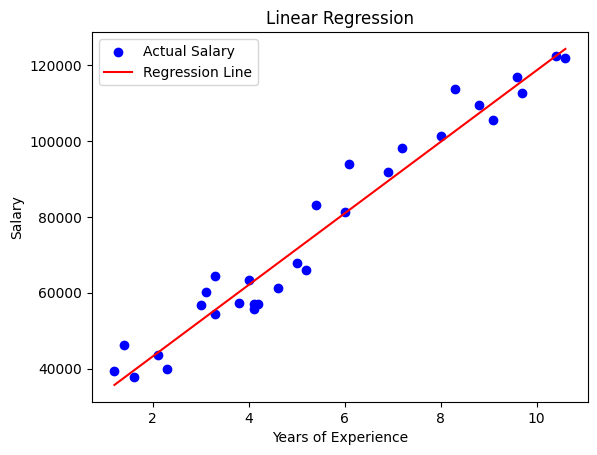

Predicted salary for 5 years: 71499.2780946286


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
data = pd.read_csv("/content/Salary_dataset.csv")

print("First five rows:")
print(data.head())

# Select input and output
X = data[["YearsExperience"]]
y = data["Salary"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict salary
y_pred = model.predict(X_test)

# Display results
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# Plot regression line
plt.scatter(X, y, color="blue", label="Actual Salary")
plt.plot(X, model.predict(X), color="red", label="Regression Line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression")
plt.legend()
plt.show()

# Predict salary for 5 years of experience
new_data = pd.DataFrame({"YearsExperience": [5]})
prediction = model.predict(new_data)
print("Predicted salary for 5 years:", prediction[0])


Polynomial Degree: 2
Mean Squared Error: 52527916.3687748
R2 Score: 0.8971645780890873


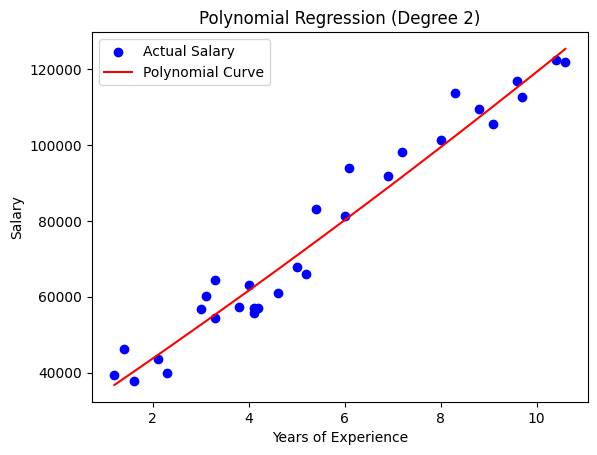

Predicted salary for 5 years: 70862.40566193899


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
data = pd.read_csv("/content/Salary_dataset.csv")

# Select input and output
X = data[["YearsExperience"]]
y = data["Salary"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert input into polynomial features
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Train polynomial regression model
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Make predictions
y_pred = model.predict(X_test_poly)

# Display results
print("Polynomial Degree: 2")
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# Draw polynomial curve
X_curve = pd.DataFrame({
    "YearsExperience": sorted(X["YearsExperience"])
})
X_curve_poly = poly.transform(X_curve)
y_curve = model.predict(X_curve_poly)

plt.scatter(X, y, color="blue", label="Actual Salary")
plt.plot(X_curve, y_curve, color="red", label="Polynomial Curve")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Polynomial Regression (Degree 2)")
plt.legend()
plt.show()

# Predict salary for 5 years of experience
new_data = pd.DataFrame({"YearsExperience": [5]})
new_poly = poly.transform(new_data)
prediction = model.predict(new_poly)
print("Predicted salary for 5 years:", prediction[0])
